In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import sklearn.metrics as metrics

In [7]:
import warnings
warnings.filterwarnings('ignore')

#### Load dataset

In [8]:
df = pd.read_excel('C:\\Users\\saher\\OneDrive\\Documents\\Intership_Projects\\Apple_iPhone_Sales_Analysis\\data\\raw\\iPhone_India_Shipments_2020_2026.xlsx')

In [9]:
train_df = df.dropna(subset=['Annual_Shipments_Million']).copy()

In [10]:
X = train_df[['Year']]  # Features (Independent variable)
y = train_df['Annual_Shipments_Million']  # Target (Dependent variable)

In [11]:
print("Training Data Loaded Successfully:")
display(train_df[['Year', 'Annual_Shipments_Million']])

Training Data Loaded Successfully:


,Year,Annual_Shipments_Million
0,2020,3.2
1,2021,4.2
2,2022,5.2
3,2023,6.2
4,2024,7.2
5,2025,8.2


#### Build & Compare Forecasting Models

In [12]:
# 1. Naive Forecast (Assumes next year equals the last observed value)
naive_forecast_2027 = y.iloc[-1]
print("Naive Forecast for 2027:",
      round(naive_forecast_2027, 2),
      "Million")

Naive Forecast for 2027: 8.2 Million


In [13]:
# 2. Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2017
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [14]:
# Predict for 2027
forecast_2027 = lr_model.predict([[2027]])[0]

print(f"Naive Forecast for 2027: {naive_forecast_2027:.2f} Million units")
print(f"Linear Regression Forecast for 2027: {forecast_2027:.2f} Million units")

Naive Forecast for 2027: 8.20 Million units
Linear Regression Forecast for 2027: 10.20 Million units


In [15]:
pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [16]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Build Holt's Linear Trend Model

holt_model = ExponentialSmoothing(
    y,
    trend='add',
    damped_trend=True,
    initialization_method='estimated'
)

# Train the model

holt_fit = holt_model.fit()

# Forecast two years ahead (2026 and 2027)

holt_forecast = holt_fit.forecast(steps=2)

# Extract 2027 forecast

forecast_2027_holt = holt_forecast.iloc[1]

print("Holt Forecast for 2027:",
      round(forecast_2027_holt, 2),
      "Million")

Holt Forecast for 2027: 10.17 Million


#### Model Evaluation (MAE & RMSE)

In [19]:
results = []

for i in range(2, len(train_df)):

    train = train_df.iloc[:i]

    test = train_df.iloc[i]

    actual = test['Annual_Shipments_Million']

    # Model 1: Naive

    naive_pred = train['Annual_Shipments_Million'].iloc[-1]

    # Model 2: Linear Regression

    lr = LinearRegression()

    lr.fit(
        train[['Year']],
        train['Annual_Shipments_Million']
    )

    lr_pred = lr.predict(
        pd.DataFrame({'Year': [test['Year']]})
    )[0]

    # Model 3: Holt's Exponential Smoothing

    holt = ExponentialSmoothing(
        train['Annual_Shipments_Million'],
        trend='add',
        damped_trend=True,
        initialization_method='estimated'
    ).fit()

    holt_pred = holt.forecast(1).iloc[0]

    results.append({
        'Year': test['Year'],
        'Actual': actual,
        'Naive': naive_pred,
        'Linear Regression': lr_pred,
        'Holt': holt_pred
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Year,Actual,Naive,Linear Regression,Holt
0,2022,5.2,4.2,5.2,5.174024
1,2023,6.2,5.2,6.2,6.192501
2,2024,7.2,6.2,7.2,7.190001
3,2025,8.2,7.2,8.2,8.187500


In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [22]:

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return mae, rmse, mape


model_results = []

for model_name in ['Naive', 'Linear Regression', 'Holt']:

    mae, rmse, mape = evaluate_model(
        comparison_df['Actual'],
        comparison_df[model_name]
    )

    model_results.append({
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

model_comparison = pd.DataFrame(model_results)

display(model_comparison.round(3))

,Model,MAE,RMSE,MAPE
0,Naive,1.000,1.000,15.361
1,Linear Regression,0.000,0.000,0.000
2,Holt,0.014,0.016,0.228


#### Visualization (Historical vs. Forecast)

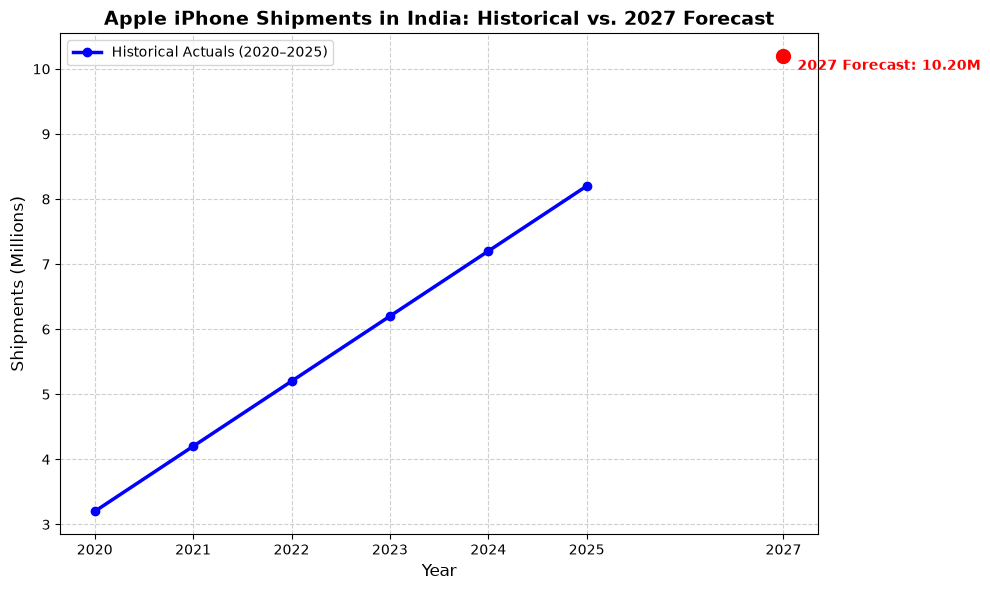

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(train_df['Year'], train_df['Annual_Shipments_Million'], marker='o', label='Historical Actuals (2020–2025)', color='blue', linewidth=2.5)

# Plot 2027 Prediction
plt.scatter([2027], [forecast_2027], color='red', s=100, zorder=5)
plt.annotate(f"2027 Forecast: {forecast_2027:.2f}M", (2027, forecast_2027), textcoords="offset points", xytext=(10,-10), fontweight='bold', color='red')

plt.title('Apple iPhone Shipments in India: Historical vs. 2027 Forecast', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Shipments (Millions)', fontsize=12)
plt.xticks(list(train_df['Year']) + [2027])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Compare all three forecasting models

forecast_comparison = pd.DataFrame({

    'Model': [
        'Naive Forecast',
        'Linear Regression',
        'Holt Exponential Smoothing'
    ],

    'Forecast_2027_Million': [
        naive_forecast_2027,
        forecast_2027,
        forecast_2027_holt
    ]

})

print("2027 Forecast Comparison:")
display(forecast_comparison.round(3))

2027 Forecast Comparison:


,Model,Forecast_2027_Million
0,Naive Forecast,8.200
1,Linear Regression,10.200
2,Holt Exponential Smoothing,10.165


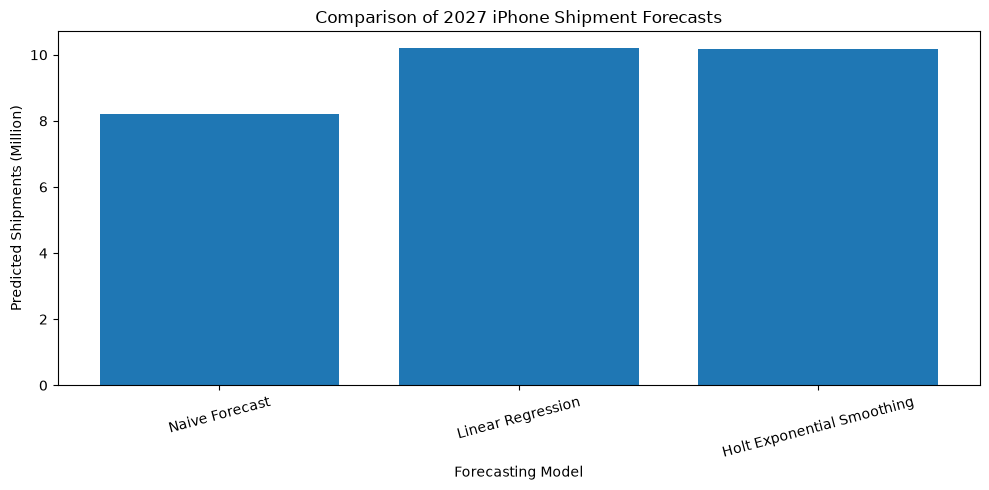

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    forecast_comparison['Model'],
    forecast_comparison['Forecast_2027_Million']
)

plt.title('Comparison of 2027 iPhone Shipment Forecasts')

plt.xlabel('Forecasting Model')

plt.ylabel('Predicted Shipments (Million)')

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

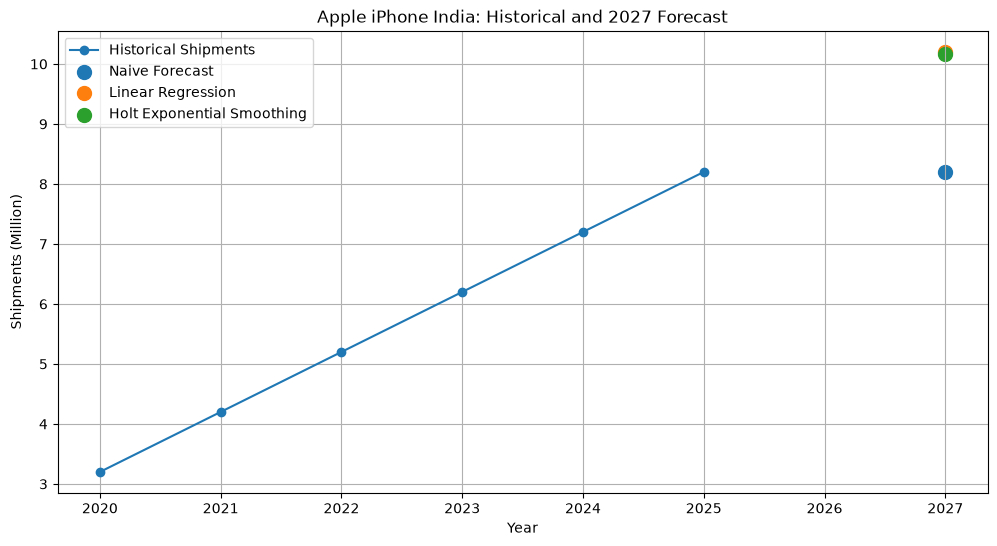

In [27]:
plt.figure(figsize=(12,6))

# Historical data

plt.plot(
    train_df['Year'],
    train_df['Annual_Shipments_Million'],
    marker='o',
    label='Historical Shipments'
)

# Forecast values

for _, row in forecast_comparison.iterrows():

    plt.scatter(
        2027,
        row['Forecast_2027_Million'],
        s=100,
        label=row['Model']
    )

plt.title('Apple iPhone India: Historical and 2027 Forecast')

plt.xlabel('Year')

plt.ylabel('Shipments (Million)')

plt.legend()

plt.grid(True)

plt.show()